In [ ]:
import numpy as np
import torch

from torchgeo_bench.coordbench.datasets import load_era5_ecmwf
from torchgeo_bench.coordbench.models import TemporalSatCLIPEncoder
from torchgeo_bench.coordbench.temporal_aggregation import discretize_dataset_and_aggregate_embeddings
from torchgeo_bench.coordbench.probe import linear_probe_score, spatial_fold_ids

In [2]:
(era5,) = load_era5_ecmwf(subsample_locations=True)
print(era5.name, era5.posix_timestamp.shape, list(era5.tasks.keys()))

/home/libe2152/projects/torchgeo-bench/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


era5_ecmwf (3650000,) ['d2m', 't2m', 'stl1', 'stl2', 'stl3', 'stl4', 'swvl1', 'swvl2', 'swvl3', 'swvl4', 'ssrd', 'strd', 'sde', 'snowc', 'u10', 'v10', 'sp', 'tp', 'skt']


In [3]:
encoder = TemporalSatCLIPEncoder(
    ckpt_path="/home/libe2152/projects/temporal-satclip/ckpts/tsatclip-doy-1M.ckpt",
    repo_path="/home/libe2152/projects/temporal-satclip/",
    model_name="tsatclip/doy",
    device="cuda",  # or "cpu"
)

/home/libe2152/projects/torchgeo-bench/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


using pretrained moco vit16
using loss function: satclip_loss
using temporal model: True


# Discretize to specified resolution and aggregate

This returns dict with keys mean/min/max/std/slope/total_variation

In [5]:
RESOLUTION = "monthly"

In [6]:
discretized, embeddings = discretize_dataset_and_aggregate_embeddings(
    era5, encoder, discretization_method=RESOLUTION
)
print({k: v.shape for k, v in embeddings.items()})

Discretized dataset in 2.56 seconds. 120000 locations, 30 timestamps per location.


/home/libe2152/projects/torchgeo-bench/src/torchgeo_bench/coordbench/models.py:381: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  [torch.as_tensor(lat), torch.as_tensor(lon), torch.as_tensor(posix_timestamp)], dim=1


Aggregated embeddings in 123.93 seconds. 120000 locations, 256 embedding dimensions.
{'mean': torch.Size([120000, 256]), 'min': torch.Size([120000, 256]), 'max': torch.Size([120000, 256]), 'std': torch.Size([120000, 256]), 'slope': torch.Size([120000, 256]), 'total_variation': torch.Size([120000, 256])}


In [9]:
discretized.tasks

{'d2m_mean': array([240.9682 , 232.70576, 223.16087, ..., 252.30019, 244.13646,
        244.03828], shape=(120000,), dtype=float32),
 'd2m_min': array([235.42854, 227.00795, 213.15382, ..., 245.61247, 239.13579,
        237.85838], shape=(120000,), dtype=float32),
 'd2m_max': array([245.84013, 238.10414, 236.49004, ..., 259.1586 , 251.34875,
        250.70445], shape=(120000,), dtype=float32),
 't2m_mean': array([244.5604 , 236.41592, 227.04283, ..., 256.09802, 250.25995,
        248.0806 ], shape=(120000,), dtype=float32),
 't2m_min': array([238.87785, 230.64587, 217.2451 , ..., 249.50403, 242.22539,
        241.58543], shape=(120000,), dtype=float32),
 't2m_max': array([249.73555, 241.65808, 239.77788, ..., 265.29285, 261.9551 ,
        254.96147], shape=(120000,), dtype=float32),
 'stl1_mean': array([232.18735, 231.87933, 229.90097, ..., 254.6422 , 251.2162 ,
        249.0878 ], shape=(120000,), dtype=float32),
 'stl1_min': array([231.23523, 231.27339, 228.3573 , ..., 253.27136, 250

# Try regression
For now, just specify an ERA5 target.

In [31]:
target_key = 'tp_mean'

In [32]:
y = discretized.tasks[target_key].astype(np.float32)
print(f"Target: {target_key}, N={len(y)}")

Target: tp_mean, N=120000


In [33]:
# Run both random and spatial CV for a given feature matrix
def evaluate(X: np.ndarray, label: str) -> None:
    score_rand, folds_rand = linear_probe_score(X, y, task_type="regression")
    score_spat, folds_spat = linear_probe_score(X, y, task_type="regression", fold_assign=spatial_folds)
    print(f"{label}")
    print(f"  random   R² = {np.mean(folds_rand):.4f} ± {np.std(folds_rand):.4f}")
    print(f"  spatial  R² = {np.mean(folds_spat):.4f} ± {np.std(folds_spat):.4f}")

In [34]:
# Spatial fold ids for block-CV split
spatial_folds = spatial_fold_ids(discretized.lat, discretized.lon, folds=5, cell_deg=10.0)

## Mean only

In [40]:
evaluate(embeddings["mean"].numpy(), "mean")

mean
  random   R² = 0.5340 ± 0.0077
  spatial  R² = 0.4379 ± 0.0239


In [65]:
X_mean_slope = torch.cat([embeddings["mean"], embeddings["slope"]], dim=1).numpy()
evaluate(X_mean_slope, "mean + slope")

/home/libe2152/projects/torchgeo-bench/src/torchgeo_bench/coordbench/probe.py:251: UserWarning: ridge alpha selected at grid edge; widen RIDGE_ALPHAS
  _, fold_scores = _cv_alpha_scores(data, fold_ids, alphas, standardize=standardize)


mean + slope
  random   R² = 0.5921 ± 0.0080
  spatial  R² = 0.4985 ± 0.0254


## Compile/Plot Results

In [47]:
import matplotlib.pyplot as plt

In [48]:
from itertools import combinations

In [46]:
results = {} 

def evaluate(X: np.ndarray, label: str) -> None:
    _, folds_rand = linear_probe_score(X, y, task_type="regression")
    _, folds_spat = linear_probe_score(X, y, task_type="regression", fold_assign=spatial_folds)
    results[label] = {
        "random":  (np.mean(folds_rand), np.std(folds_rand)),
        "spatial": (np.mean(folds_spat), np.std(folds_spat)),
    }
    print(f"{label}")
    print(f"  random   R² = {results[label]['random'][0]:.4f} ± {results[label]['random'][1]:.4f}")
    print(f"  spatial  R² = {results[label]['spatial'][0]:.4f} ± {results[label]['spatial'][1]:.4f}")

In [49]:
STATS = list(embeddings.keys())  # ["mean", "min", "max", "std", "slope", "total_variation"]

for r in range(1, len(STATS) + 1):
    for combo in combinations(STATS, r):
        X = np.concatenate([embeddings[s].numpy() for s in combo], axis=1)
        evaluate(X, " + ".join(combo))


mean
  random   R² = 0.5340 ± 0.0077
  spatial  R² = 0.4379 ± 0.0239
min
  random   R² = 0.5358 ± 0.0084
  spatial  R² = 0.4636 ± 0.0211
max
  random   R² = 0.5352 ± 0.0071
  spatial  R² = 0.4630 ± 0.0272
std
  random   R² = 0.3315 ± 0.0041
  spatial  R² = 0.2802 ± 0.0261
slope
  random   R² = 0.1038 ± 0.0033
  spatial  R² = 0.0758 ± 0.0134
total_variation
  random   R² = 0.3418 ± 0.0040
  spatial  R² = 0.2877 ± 0.0266
mean + min
  random   R² = 0.5850 ± 0.0086
  spatial  R² = 0.4860 ± 0.0303
mean + max
  random   R² = 0.5840 ± 0.0080
  spatial  R² = 0.4850 ± 0.0298
mean + std
  random   R² = 0.5839 ± 0.0083
  spatial  R² = 0.4890 ± 0.0248
mean + slope
  random   R² = 0.5921 ± 0.0080
  spatial  R² = 0.4985 ± 0.0254
mean + total_variation
  random   R² = 0.5864 ± 0.0083
  spatial  R² = 0.4914 ± 0.0242
min + max
  random   R² = 0.5819 ± 0.0079
  spatial  R² = 0.4877 ± 0.0277
min + std
  random   R² = 0.5812 ± 0.0080
  spatial  R² = 0.4890 ± 0.0247
min + slope
  random   R² = 0.5864 ± 0.0


Top 5 combinations by spatial CV R²:
mean + std + slope + total_variation
  random   R² = 0.6305 ± 0.0085
  spatial  R² = 0.5274 ± 0.0254
mean + min + std + slope + total_variation
  random   R² = 0.6394 ± 0.0077
  spatial  R² = 0.5272 ± 0.0243
mean + max + std + slope + total_variation
  random   R² = 0.6388 ± 0.0076
  spatial  R² = 0.5272 ± 0.0243
min + std + slope + total_variation
  random   R² = 0.6285 ± 0.0082
  spatial  R² = 0.5271 ± 0.0237
max + std + slope + total_variation
  random   R² = 0.6283 ± 0.0083
  spatial  R² = 0.5270 ± 0.0237

Worst 5 combinations by spatial CV R²:
slope
  random   R² = 0.1038 ± 0.0033
  spatial  R² = 0.0758 ± 0.0134
std
  random   R² = 0.3315 ± 0.0041
  spatial  R² = 0.2802 ± 0.0261
total_variation
  random   R² = 0.3418 ± 0.0040
  spatial  R² = 0.2877 ± 0.0266
std + total_variation
  random   R² = 0.3912 ± 0.0054
  spatial  R² = 0.3199 ± 0.0209
std + slope
  random   R² = 0.4115 ± 0.0055
  spatial  R² = 0.3294 ± 0.0187

Top 5 combinations by rand

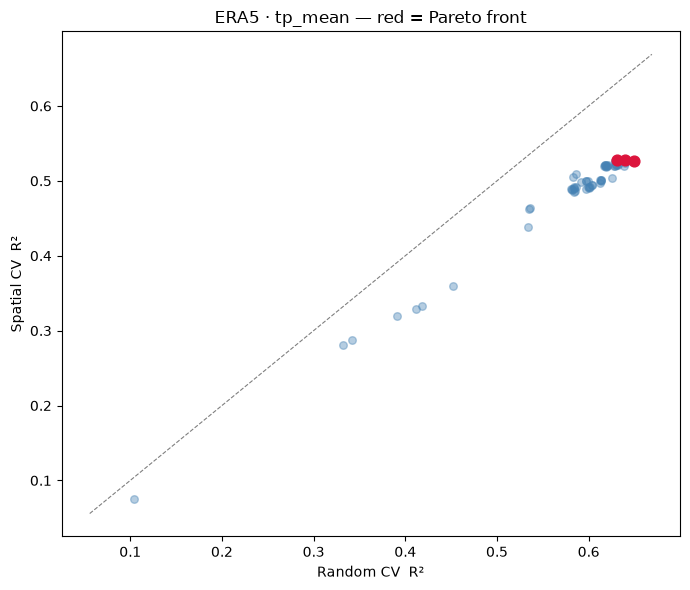

In [ ]:
fig, ax = plt.subplots(figsize=(7, 6))

rx_all = np.array([results[l]["random"][0] for l in results])
sy_all = np.array([results[l]["spatial"][0] for l in results])
labels = list(results.keys())

# Pareto front: not dominated by any other point on both axes
def is_pareto(rx, sy):
    return np.array([
        not any((rx[j] >= rx[i] and sy[j] >= sy[i] and (rx[j] > rx[i] or sy[j] > sy[i]))
                for j in range(len(rx)))
        for i in range(len(rx))
    ])

pareto_mask = is_pareto(rx_all, sy_all)

ax.scatter(rx_all[~pareto_mask], sy_all[~pareto_mask], color="steelblue", alpha=0.4, s=30)
ax.scatter(rx_all[pareto_mask], sy_all[pareto_mask], color="crimson", s=60, zorder=5)

lims = [min(rx_all.min(), sy_all.min()) - 0.02, max(rx_all.max(), sy_all.max()) + 0.02]
ax.plot(lims, lims, "k--", linewidth=0.8, alpha=0.5)
ax.set_xlabel("Random CV  R²")
ax.set_ylabel("Spatial CV  R²")
ax.set_title(f"ERA5 · {target_key} — red = Pareto front")
plt.tight_layout()

In [62]:
print(f"Pareto front combinations ({pareto_mask.sum()}):")
for label in np.array(labels)[pareto_mask]:
    rx, rx_err = results[label]["random"]
    sy, sy_err = results[label]["spatial"]
    print(f"{label}")
    print(f"  random   R² = {rx:.4f} ± {rx_err:.4f}")
    print(f"  spatial  R² = {sy:.4f} ± {sy_err:.4f}")

Pareto front combinations (3):
mean + std + slope + total_variation
  random   R² = 0.6305 ± 0.0085
  spatial  R² = 0.5274 ± 0.0254
mean + min + std + slope + total_variation
  random   R² = 0.6394 ± 0.0077
  spatial  R² = 0.5272 ± 0.0243
mean + min + max + std + slope + total_variation
  random   R² = 0.6490 ± 0.0070
  spatial  R² = 0.5268 ± 0.0248


In [64]:
print("Mean only results:")
print(f"  random   R² = {results['mean']['random'][0]:.4f} ± {results['mean']['random'][1]:.4f}")
print(f"  spatial  R² = {results['mean']['spatial'][0]:.4f} ± {results['mean']['spatial'][1]:.4f}")

sorted_labels = sorted(results, key=lambda l: results[l]["spatial"][0], reverse=True)[:5]
print("\nTop 5 combinations by spatial CV R²:")
for label in sorted_labels:
    rx, rx_err = results[label]["random"]
    sy, sy_err = results[label]["spatial"]
    print(f"{label}")
    print(f"  random   R² = {rx:.4f} ± {rx_err:.4f}")
    print(f"  spatial  R² = {sy:.4f} ± {sy_err:.4f}")

print("\nWorst 5 combinations by spatial CV R²:")
sorted_labels = sorted(results, key=lambda l: results[l]["spatial"][0])[:5]
for label in sorted_labels:
    rx, rx_err = results[label]["random"]
    sy, sy_err = results[label]["spatial"]
    print(f"{label}")
    print(f"  random   R² = {rx:.4f} ± {rx_err:.4f}")
    print(f"  spatial  R² = {sy:.4f} ± {sy_err:.4f}")

print("\nTop 5 combinations by random CV R²:")
sorted_labels = sorted(results, key=lambda l: results[l]["random"][0], reverse=True)[:5]
for label in sorted_labels:
    rx, rx_err = results[label]["random"]
    sy, sy_err = results[label]["spatial"]
    print(f"{label}")
    print(f"  random   R² = {rx:.4f} ± {rx_err:.4f}")
    print(f"  spatial  R² = {sy:.4f} ± {sy_err:.4f}")

print("\nWorst 5 combinations by random CV R²:")
sorted_labels = sorted(results, key=lambda l: results[l]["random"][0])[:5]
for label in sorted_labels:
    rx, rx_err = results[label]["random"]
    sy, sy_err = results[label]["spatial"]
    print(f"{label}")
    print(f"  random   R² = {rx:.4f} ± {rx_err:.4f}")
    print(f"  spatial  R² = {sy:.4f} ± {sy_err:.4f}")

Mean only results:
  random   R² = 0.5340 ± 0.0077
  spatial  R² = 0.4379 ± 0.0239

Top 5 combinations by spatial CV R²:
mean + std + slope + total_variation
  random   R² = 0.6305 ± 0.0085
  spatial  R² = 0.5274 ± 0.0254
mean + min + std + slope + total_variation
  random   R² = 0.6394 ± 0.0077
  spatial  R² = 0.5272 ± 0.0243
mean + max + std + slope + total_variation
  random   R² = 0.6388 ± 0.0076
  spatial  R² = 0.5272 ± 0.0243
min + std + slope + total_variation
  random   R² = 0.6285 ± 0.0082
  spatial  R² = 0.5271 ± 0.0237
max + std + slope + total_variation
  random   R² = 0.6283 ± 0.0083
  spatial  R² = 0.5270 ± 0.0237

Worst 5 combinations by spatial CV R²:
slope
  random   R² = 0.1038 ± 0.0033
  spatial  R² = 0.0758 ± 0.0134
std
  random   R² = 0.3315 ± 0.0041
  spatial  R² = 0.2802 ± 0.0261
total_variation
  random   R² = 0.3418 ± 0.0040
  spatial  R² = 0.2877 ± 0.0266
std + total_variation
  random   R² = 0.3912 ± 0.0054
  spatial  R² = 0.3199 ± 0.0209
std + slope
  random